# 02 — Radiometric Preprocessing (Illumination Normalization)

**Input:** `26166_DATA/processed/geotiff/{instrument}/*.tif` from Notebook 01
**Output:** `26166_DATA/processed/radiometric/{instrument}/*.tif`


In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

import os, csv
import numpy as np
import rasterio
import cv2
import matplotlib.pyplot as plt

DRIVE_ROOT = '/content/drive/MyDrive/26166_DATA'
IN_ROOT    = f'{DRIVE_ROOT}/processed/geotiff'
OUT_ROOT   = f'{DRIVE_ROOT}/processed/radiometric'
os.makedirs(OUT_ROOT, exist_ok=True)

with open(f'{DRIVE_ROOT}/processed/manifest.csv') as f:
    manifest_rows = list(csv.DictReader(f))
print(f'{len(manifest_rows)} products in manifest')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
3 products in manifest


## 1. Build a matchable single-band grayscale for every product

In [6]:
import gc
import numpy as np
import cv2
import rasterio
from rasterio.windows import Window

# ---------- helper 1: cheap percentile estimate (decimated read, not full array) ----------
def estimate_percentiles(path, band=1, max_dim=2000, low_pct=1, high_pct=99):
    with rasterio.open(path) as src:
        scale = max(1, max(src.height, src.width) // max_dim)
        small = src.read(band, out_shape=(src.height // scale, src.width // scale)).astype(np.float32)
    valid = small[np.isfinite(small)]
    lo, hi = np.percentile(valid, [low_pct, high_pct])
    del small
    return lo, hi

# ---------- helper 2: blockwise CLAHE ----------
def blockwise_stretch_and_clahe(path, out_path, band, lo, hi, tx=8, ty_total=8, clip_limit=2.0):
    with rasterio.open(path) as src:
        H, W = src.height, src.width
        tile_h = -(-H // ty_total)
        profile = {'driver': 'GTiff', 'height': H, 'width': W, 'count': 1, 'dtype': 'uint8'}
        with rasterio.open(out_path, 'w', **profile) as dst:
            for ty in range(ty_total):
                y0, y1 = ty * tile_h, min(H, (ty + 1) * tile_h)
                if y0 >= H:
                    break
                pad0 = tile_h if ty > 0 else 0
                pad1 = tile_h if y1 + tile_h <= H else max(0, H - y1)
                ry0, ry1 = y0 - pad0, y1 + pad1
                window = Window(0, ry0, W, ry1 - ry0)

                block = src.read(band, window=window).astype(np.float32)
                block = np.clip((block - lo) / max(hi - lo, 1e-6), 0, 1)
                block_u8 = (block * 255).astype(np.uint8)

                n_tiles_y = max(1, round((ry1 - ry0) / tile_h))
                clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(tx, n_tiles_y))
                block_clahe = clahe.apply(block_u8)

                core = block_clahe[pad0:pad0 + (y1 - y0), :]
                dst.write(core, 1, window=Window(0, y0, W, y1 - y0))
                del block, block_u8, block_clahe, core
            gc.collect()

# ---------- helper 3: IIRS PCA without loading the full cube ----------
def iirs_pca_project_streaming(path, out_tmp_path, sample_rows=200, n_row_samples=5):
    with rasterio.open(path) as src:
        bands, H, W = src.count, src.height, src.width
        rng = np.random.default_rng(0)

        samples = []
        for _ in range(n_row_samples):
            y0 = int(rng.integers(0, max(1, H - sample_rows)))
            block = src.read(window=Window(0, y0, W, min(sample_rows, H - y0))).astype(np.float32)
            samples.append(block.reshape(bands, -1).T)
            del block
        flat = np.concatenate(samples, axis=0)
        flat -= flat.mean(axis=0, keepdims=True)
        _, _, vt = np.linalg.svd(flat, full_matrices=False)
        weights = vt[0]
        del samples, flat
        gc.collect()

        proj = np.zeros((H, W), dtype=np.float32)
        for b in range(1, bands + 1):
            band_data = src.read(b).astype(np.float32)
            proj += band_data * weights[b - 1]
            del band_data

        profile = {'driver': 'GTiff', 'height': H, 'width': W, 'count': 1, 'dtype': 'float32'}
        with rasterio.open(out_tmp_path, 'w', **profile) as dst:
            dst.write(proj, 1)
        del proj
        gc.collect()

## 2. Illumination-invariance: CLAHE (+ optional homomorphic filtering)

In [7]:
def apply_clahe(img_u8, clip_limit=2.0, tile_size=8):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(tile_size, tile_size))
    return clahe.apply(img_u8)

def homomorphic_filter(img_u8, gamma_low=0.5, gamma_high=1.5, cutoff=30):
    img = img_u8.astype(np.float32) + 1.0
    log_img = np.log(img)
    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2
    u, v = np.meshgrid(np.arange(cols) - ccol, np.arange(rows) - crow)
    d = np.sqrt(u**2 + v**2)
    h = (gamma_high - gamma_low) * (1 - np.exp(-(d**2) / (2 * (cutoff**2)))) + gamma_low
    fft = np.fft.fftshift(np.fft.fft2(log_img))
    img_back = np.fft.ifft2(np.fft.ifftshift(fft * h)).real
    return to_uint8(np.exp(img_back) - 1.0)


## 3. Run over every converted product

In [8]:
processed_rows = []

for row in manifest_rows:
    instrument = row['instrument']
    out_dir = f'{OUT_ROOT}/{instrument}'
    os.makedirs(out_dir, exist_ok=True)
    out_path = f"{out_dir}/{row['product']}.tif"

    if instrument == 'iirs':
        tmp_path = f"{out_dir}/{row['product']}_pc1_tmp.tif"
        iirs_pca_project_streaming(row['geotiff_path'], tmp_path)
        source_for_stretch = tmp_path
    else:
        source_for_stretch = row['geotiff_path']

    lo, hi = estimate_percentiles(source_for_stretch, band=1)
    blockwise_stretch_and_clahe(source_for_stretch, out_path, band=1, lo=lo, hi=hi)

    if instrument == 'iirs':
        os.remove(tmp_path)

    processed_rows.append({**row, 'radiometric_path': out_path})
    print(f"{instrument}/{row['product']}: done")
    gc.collect()

print(f'\nProcessed {len(processed_rows)} products.')

ohrc/ch2_ohr_ncp_20220914T0835371412_d_img_d32: done
tmc2/ch2_tmc_ncn_20191125T0749024692_d_img_d18: done
iirs/ch2_iir_nri_20220221T1109265965_d_img_d18: done

Processed 3 products.


## 4. Before / after visual check

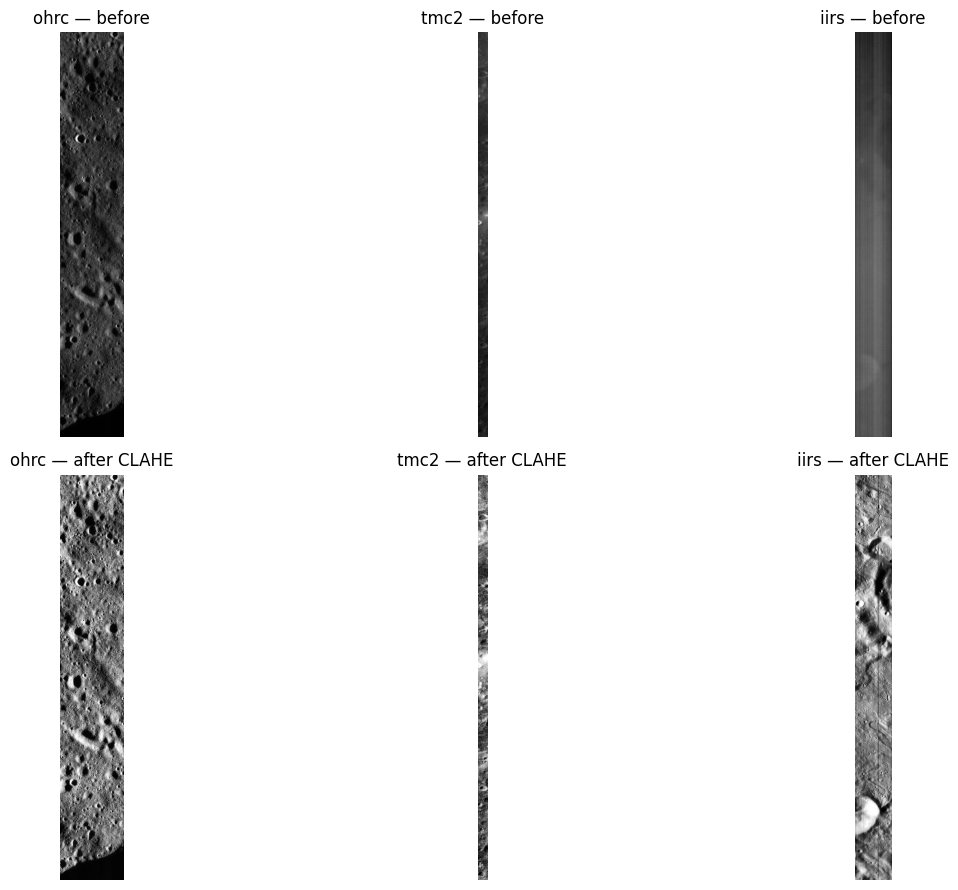

In [9]:
import matplotlib.pyplot as plt

def load_decimated(path, band=1, max_dim=1500):
    with rasterio.open(path) as src:
        scale = max(1, max(src.height, src.width) // max_dim)
        return src.read(band, out_shape=(src.height // scale, src.width // scale))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for col, instrument in enumerate(['ohrc', 'tmc2', 'iirs']):
    rows = [r for r in processed_rows if r['instrument'] == instrument]
    if not rows:
        continue
    r = rows[0]

    raw_u8_small = load_decimated(r['geotiff_path'], band=1)
    processed_small = load_decimated(r['radiometric_path'], band=1)

    axes[0, col].imshow(raw_u8_small, cmap='gray')
    axes[0, col].set_title(f'{instrument} — before'); axes[0, col].axis('off')
    axes[1, col].imshow(processed_small, cmap='gray')
    axes[1, col].set_title(f'{instrument} — after CLAHE'); axes[1, col].axis('off')

plt.tight_layout(); plt.show()

In [10]:
out_manifest = f'{DRIVE_ROOT}/processed/manifest_radiometric.csv'
with open(out_manifest, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=processed_rows[0].keys())
    writer.writeheader()
    writer.writerows(processed_rows)
print('Saved', out_manifest)


Saved /content/drive/MyDrive/26166_DATA/processed/manifest_radiometric.csv


---
Next notebook: **03_geometric_preprocess.ipynb**